# DPLL sobre la forma clausal de Tseitin — Proyecto Ciclo Hamiltoniano

Resolvemos el problema del ciclo hamiltoniano con **DPLL**. Este notebook hace tres cosas:

1. **Tseitin:** pasa cada regla (y las cinco juntas) a forma clausal con `tseitin` (de `logica.py`) y guarda el resultado en `datos/tseitin.json`.
2. **DPLL:** implementa el algoritmo (propagación de unitarias, literales puros y ramificación) y lo corre regla por regla y con las cinco reglas juntas.
3. **Verificación:** comprueba el modelo contra las reglas originales, cuenta todos los recorridos posibles y prueba un grafo sin ciclo (insatisfacible).

Los tiempos y el número de decisiones quedan en `resultados/resultados_DPLL.csv`, con el mismo formato que los otros solvers.

## Implementación en reglas del proyecto

Usamos **DPLL** con las reglas de nuestro proyecto (`problema.py`): un grafo de 5 ciudades y 7 carreteras, con el descriptor $Visita(c,t)$ = «la ciudad $c$ se visita en la posición $t$» (25 letras proposicionales).

DPLL trabaja con formas clausales, así que primero pasamos las reglas por **Tseitin**. Después corremos **cada regla por separado** y luego **las cinco juntas**, midiendo el tiempo con `%%time`.

Ciudades: ['Baq', 'Buc', 'Bog', 'Med', 'Per']
Letras proposicionales Visita(c,t): 25


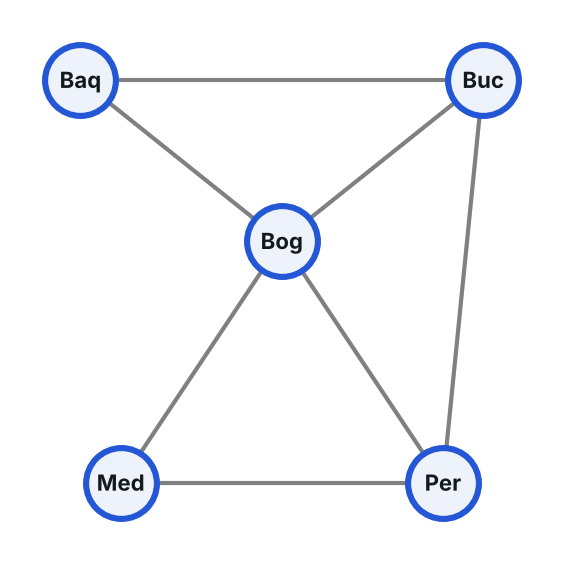

In [1]:
import os, sys, time, json
import pandas as pd
from itertools import permutations
from logica import *
from problema import CicloHamiltoniano

sys.setrecursionlimit(10000)   # las reglas son fórmulas largas (recursión profunda)
os.makedirs('datos', exist_ok=True)
os.makedirs('resultados', exist_ok=True)

ciudades = ['Baq', 'Buc', 'Bog', 'Med', 'Per']
aristas  = [{0,1}, {1,2}, {2,3}, {3,4}, {2,4}, {0,2}, {1,4}]
coords   = {0:(0,3), 1:(3,3), 2:(1.5,1.8), 3:(0.3,0), 4:(2.7,0)}   # solo para dibujar

H = CicloHamiltoniano(ciudades, aristas, coords)
print('Ciudades:', ciudades)
print('Letras proposicionales Visita(c,t):', H.n * H.n)

# --- Registro de resultados (alimenta la tabla resumen del final) ---
SOLVER = 'DPLL'
resultados = {}
modelos = {}

H.dibujar_grafo()

## Transformación de Tseitin

DPLL trabaja con **formas clausales**: una lista de cláusulas, y cada cláusula es una lista de literales (`'-x'` es la negación de `x`). Para no explotar el tamaño al pasar una fórmula a FNC, Tseitin le da a **cada conectivo una letra nueva** $x_i$ con la equivalencia $x_i \leftrightarrow$ (subfórmula), y cada equivalencia se escribe con 2 a 4 cláusulas (`a_clausal`). Al final se agrega la cláusula unitaria $[x_{raiz}]$: la fórmula completa debe ser verdadera.

Un ejemplo pequeño, con $p \wedge \neg q$ (`'(pY-q)'`):

In [2]:
ej = '(pY-q)'
C_ej = tseitin(ej)

# Nombres legibles: las letras auxiliares (códigos grandes) se muestran como x1, x2, ...
letras_ej = sorted(inorder_to_tree(ej).letras())
aux = sorted({l.lstrip('-') for cl in C_ej for l in cl} - set(letras_ej))
nombre = {**{l: l for l in letras_ej}, **{l: f'x{i + 1}' for i, l in enumerate(aux)}}
legible = lambda lit: ('¬' if lit[0] == '-' else '') + nombre[lit.lstrip('-')]

print('Fórmula:', ej, '  ->  x1 = ¬q,  x2 = (p ∧ x1)')
for cl in C_ej:
    print('  ', ' ∨ '.join(legible(l) for l in cl))

Fórmula: (pY-q)   ->  x1 = ¬q,  x2 = (p ∧ x1)
   x2
   ¬x1 ∨ ¬q
   x1 ∨ q
   p ∨ ¬x2
   x1 ∨ ¬x2
   ¬p ∨ ¬x1 ∨ x2


### Tseitin de las reglas

Aplicamos `tseitin` a cada regla y a las cinco juntas (`Ytoria(H.reglas)`). Registramos el tiempo, los conectivos de la fórmula, el número de cláusulas y las letras de la forma clausal (originales + auxiliares).

In [3]:
formulas = {f'Regla {k + 1}': H.reglas[k] for k in range(5)}
formulas['Reglas 1 a 5'] = Ytoria(H.reglas)

arboles   = {nombre: inorder_to_tree(f) for nombre, f in formulas.items()}
clausulas = {}          # nombre -> forma clausal
t_tseitin = {}          # nombre -> segundos que tardó tseitin
filas = []

for nombre, f in formulas.items():
    t0 = time.perf_counter()
    clausulas[nombre] = tseitin(f)
    t_tseitin[nombre] = time.perf_counter() - t0
    C = clausulas[nombre]
    filas.append({'Fórmula': nombre,
                  'Conectivos': arboles[nombre].num_conec(),
                  'Nº cláusulas': len(C),
                  'Nº letras': len({l.lstrip('-') for cl in C for l in cl}),
                  'Tseitin (s)': round(t_tseitin[nombre], 4)})
pd.DataFrame(filas)

,Fórmula,Conectivos,Nº cláusulas,Nº letras,Tseitin (s)
0,Regla 1,24,73,49,0.0001
1,Regla 2,24,73,49,0.0001
2,Regla 3,149,423,174,0.0011
3,Regla 4,75,226,100,0.0005
4,Regla 5,18,55,28,0.0001
5,Reglas 1 a 5,294,858,319,0.0018


### Guardar la forma clausal

Guardamos la forma clausal de cada regla en `datos/tseitin.json` (un diccionario `nombre -> lista de cláusulas`) para calcularla **una sola vez**: los demás solvers que trabajan con cláusulas (WalkSAT, MiniSAT) la leen de ahí. Las letras de código grande quedan escritas como `\uXXXX`, así que el archivo es ASCII y se lee igual en cualquier sistema.

In [4]:
# Forma: cada cláusula es una lista de str (literales)
for nombre, C in clausulas.items():
    assert all(isinstance(cl, list) and all(isinstance(l, str) for l in cl) for cl in C), nombre

with open('datos/tseitin.json', 'w') as f:
    json.dump(clausulas, f)

# Leemos el archivo y comprobamos que es lo mismo que calculamos
with open('datos/tseitin.json') as f:
    clausulas = json.load(f)
print('Guardado datos/tseitin.json con', len(clausulas), 'formas clausales:',
      {n: len(C) for n, C in clausulas.items()})

Guardado datos/tseitin.json con 6 formas clausales: {'Regla 1': 73, 'Regla 2': 73, 'Regla 3': 423, 'Regla 4': 226, 'Regla 5': 55, 'Reglas 1 a 5': 858}


## DPLL

DPLL decide si una forma clausal es satisfacible. Trabaja siempre con la forma clausal **simplificada** por las asignaciones hechas hasta el momento:

* **Asignar un literal $l$** (hacerlo verdadero): se borran las cláusulas que contienen $l$ (ya se cumplen) y se quita $\neg l$ de las demás.
* Si aparece la **cláusula vacía** `[]`, esa rama es un **conflicto**: no tiene modelo.
* Si **no queda ninguna cláusula**, todas se cumplen: lo asignado hasta aquí es un **modelo**.

En cada llamada, `dpll_rec` hace, en este orden:

1. **Propagación de unitarias:** una cláusula con un solo literal obliga a hacerlo verdadero.
2. **Literal puro:** si una letra aparece siempre con el mismo signo, se le da el valor que satisface todas sus cláusulas.
3. **Ramificación (decisión):** escoge un literal $l$ y prueba con $l$ verdadero; si esa rama no tiene modelo, vuelve atrás (*backtracking*) y prueba con $\neg l$.

Para escoger $l$ hay dos heurísticas: `'corta'` (el primer literal de la cláusula más corta) y `'frecuente'` (el literal que más aparece). Las letras que quedan sin asignar al terminar pueden valer cualquier cosa.

In [5]:
def negar(lit):
    '''Literal opuesto:  p <-> -p'''
    return lit[1:] if lit[0] == '-' else '-' + lit

def letra_de(lit):
    '''Letra proposicional de un literal:  -p -> p'''
    return lit[1:] if lit[0] == '-' else lit

def asignar(clausulas, lit):
    '''Hace verdadero `lit`: quita las cláusulas que lo contienen y borra su opuesto de las demás.'''
    opuesto = negar(lit)
    nuevas = []
    for cl in clausulas:
        if lit in cl:
            continue                                   # la cláusula ya se cumple
        if opuesto in cl:
            cl = [l for l in cl if l != opuesto]       # este literal ya no puede ayudar
        nuevas.append(cl)
    return nuevas

def literal_puro(clausulas):
    '''Un literal cuyo opuesto no aparece en ninguna cláusula, o None.'''
    vistos = dict.fromkeys(l for cl in clausulas for l in cl)     # (dict: orden estable)
    for l in vistos:
        if negar(l) not in vistos:
            return l
    return None

def escoger(clausulas, heuristica):
    '''Literal sobre el que se ramifica.'''
    if heuristica == 'corta':
        return min(clausulas, key=len)[0]
    from collections import Counter
    return Counter(l for cl in clausulas for l in cl).most_common(1)[0][0]

def dpll_rec(clausulas, I, heuristica, puros, stats):
    I = dict(I)
    # 1 y 2. Propagar unitarias (y literales puros) hasta que no haya más
    while True:
        if any(len(cl) == 0 for cl in clausulas):
            stats['conflictos'] += 1
            return None                                # cláusula vacía: conflicto
        lit = next((cl[0] for cl in clausulas if len(cl) == 1), None)
        if lit is not None:
            stats['unitarias'] += 1
        elif puros and (lit := literal_puro(clausulas)) is not None:
            stats['puros'] += 1
        else:
            break
        I[letra_de(lit)] = (lit[0] != '-')
        clausulas = asignar(clausulas, lit)
    if not clausulas:
        return I                                       # todas las cláusulas se cumplen: modelo
    # 3. Decisión: primero l, y si no hay modelo, el opuesto
    lit = escoger(clausulas, heuristica)
    stats['decisiones'] += 1
    for l in (lit, negar(lit)):
        J = dict(I)
        J[letra_de(l)] = (l[0] != '-')
        resultado = dpll_rec(asignar(clausulas, l), J, heuristica, puros, stats)
        if resultado is not None:
            return resultado
    return None

def dpll(clausulas, heuristica='corta', puros=True, stats=None):
    '''DPLL sobre una forma clausal (lista de listas de literales).
    Devuelve una interpretación (dict letra -> bool, posiblemente parcial) o None si es insatisfacible.
    `stats` (dict opcional) se llena con: decisiones, unitarias, puros, conflictos.'''
    if stats is None:
        stats = {}
    for k in ('decisiones', 'unitarias', 'puros', 'conflictos'):
        stats.setdefault(k, 0)
    return dpll_rec([list(cl) for cl in clausulas], {}, heuristica, puros, stats)

### Pruebas pequeñas

Antes de usarlo con el problema, lo probamos con casos que sabemos a mano y lo comparamos con `SATtabla` sobre fórmulas pasadas por Tseitin (incluidas algunas con dobles negaciones).

In [6]:
# Satisfacible: (p ∨ q) ∧ ¬p  ->  p falso, q verdadero
assert dpll([['p', 'q'], ['-p']]) == {'p': False, 'q': True}
# Insatisfacible: las cuatro combinaciones de p y q están prohibidas
assert dpll([['p', 'q'], ['-p', 'q'], ['p', '-q'], ['-p', '-q']]) is None

# DPLL sobre Tseitin(f)  vs  SATtabla(f)
for f in ['p', '--p', '(pY-p)', '(pO-p)', '-(pO-p)', '(p=-p)', '(p=--p)', '((p>q)Y(q>-p))', '((p>q)Y((q>r)Y(-rYp)))']:
    con_dpll  = dpll(tseitin(f)) is not None
    con_tabla = inorder_to_tree(f).SATtabla() is not None
    assert con_dpll == con_tabla, f
    print(f'{f:28s} DPLL: {"satisfacible" if con_dpll else "insatisfacible":15s} SATtabla: {"satisfacible" if con_tabla else "insatisfacible"}')

p                            DPLL: satisfacible    SATtabla: satisfacible
--p                          DPLL: satisfacible    SATtabla: satisfacible
(pY-p)                       DPLL: insatisfacible  SATtabla: insatisfacible
(pO-p)                       DPLL: satisfacible    SATtabla: satisfacible
-(pO-p)                      DPLL: insatisfacible  SATtabla: insatisfacible
(p=-p)                       DPLL: insatisfacible  SATtabla: insatisfacible
(p=--p)                      DPLL: satisfacible    SATtabla: satisfacible
((p>q)Y(q>-p))               DPLL: satisfacible    SATtabla: satisfacible
((p>q)Y((q>r)Y(-rYp)))       DPLL: insatisfacible  SATtabla: insatisfacible


### Correr DPLL sobre una regla

`correr_dpll` corre DPLL sobre la forma clausal leída de `datos/tseitin.json` y guarda una fila en `resultados` (si repites una celda, su fila se actualiza, no se duplica). Para saber si el modelo es correcto, lo **verifica contra la fórmula original** de la regla (`A.valor`), no contra las cláusulas: así se comprueba también que Tseitin conserva los modelos. Las letras que DPLL dejó sin asignar se completan con `False`, y las letras auxiliares de Tseitin se ignoran.

In [7]:
def correr_dpll(nombre, heuristica='corta', puros=True):
    '''Corre DPLL sobre la forma clausal de `nombre`, verifica el modelo y registra una fila.'''
    C = clausulas[nombre]
    A = arboles[nombre]
    stats = {}
    t0 = time.perf_counter()
    I = dpll(C, heuristica, puros, stats)
    seg = time.perf_counter() - t0
    verifica = None
    if I is not None:
        J = {l: False for l in A.letras()}                   # letras que DPLL dejó libres
        J.update({l: v for l, v in I.items() if l in J})     # (se ignoran las auxiliares)
        verifica = A.valor(J)
        modelos[nombre] = I
    resultados[nombre] = {'Solver': SOLVER, 'Regla': nombre,
                          'Resultado': 'modelo' if I is not None else 'sin modelo',
                          '¿Verifica?': verifica,
                          'Tiempo (s)': round(seg, 4),
                          'Tseitin (s)': round(t_tseitin[nombre], 4),
                          'Nº cláusulas': len(C),
                          'Decisiones': stats['decisiones'],
                          'Conflictos': stats['conflictos']}
    r = resultados[nombre]
    print(f"{nombre:13s} | {r['Resultado']:10s} | ¿verifica? {str(verifica):5s} | {seg:8.4f} s | "
          f"{stats['decisiones']:3d} decisiones | {stats['unitarias']:4d} unitarias | {stats['conflictos']:3d} conflictos")
    return I

## Regla por regla

1. En cada posición hay al menos una ciudad.
2. Cada ciudad está en al menos una posición.
3. Cada ciudad está en a lo sumo una posición.
4. Transiciones válidas: posiciones consecutivas son ciudades conectadas por una carretera.
5. Cierre del ciclo: la última posición conecta con la primera.

**Regla 1**

In [8]:
%%time
I = correr_dpll('Regla 1')

Regla 1       | modelo     | ¿verifica? True  |   0.0006 s |  20 decisiones |   24 unitarias |   0 conflictos
CPU times: user 639 μs, sys: 122 μs, total: 761 μs
Wall time: 763 μs


**Regla 2**

In [9]:
%%time
I = correr_dpll('Regla 2')

Regla 2       | modelo     | ¿verifica? True  |   0.0006 s |  20 decisiones |   24 unitarias |   0 conflictos
CPU times: user 694 μs, sys: 0 ns, total: 694 μs
Wall time: 696 μs


**Regla 3**

In [10]:
%%time
I = correr_dpll('Regla 3')

Regla 3       | modelo     | ¿verifica? True  |   0.0061 s |  25 decisiones |  149 unitarias |   0 conflictos
CPU times: user 5.99 ms, sys: 365 μs, total: 6.35 ms
Wall time: 6.34 ms


**Regla 4**

In [11]:
%%time
I = correr_dpll('Regla 4')

Regla 4       | modelo     | ¿verifica? True  |   0.0020 s |  20 decisiones |   75 unitarias |   0 conflictos
CPU times: user 2.19 ms, sys: 0 ns, total: 2.19 ms
Wall time: 2.2 ms


**Regla 5**

In [12]:
%%time
I = correr_dpll('Regla 5')

Regla 5       | modelo     | ¿verifica? True  |   0.0002 s |   5 decisiones |   18 unitarias |   0 conflictos
CPU times: user 329 μs, sys: 0 ns, total: 329 μs
Wall time: 331 μs


## Las cinco reglas juntas

Es el problema completo: la forma clausal de `Ytoria(H.reglas)`. Si DPLL devuelve un modelo, ese modelo es un ciclo hamiltoniano.

In [13]:
%%time
I = correr_dpll('Reglas 1 a 5')

Reglas 1 a 5  | modelo     | ¿verifica? True  |   0.0183 s |   7 decisiones |  312 unitarias |   0 conflictos
CPU times: user 17.9 ms, sys: 280 μs, total: 18.1 ms
Wall time: 18.6 ms


### Visualización de la solución

Dibujamos el modelo con el visualizador por turnos (azul: el camino; naranja: el cierre del ciclo).

Recorrido: Per -> Med -> Bog -> Baq -> Buc -> Per


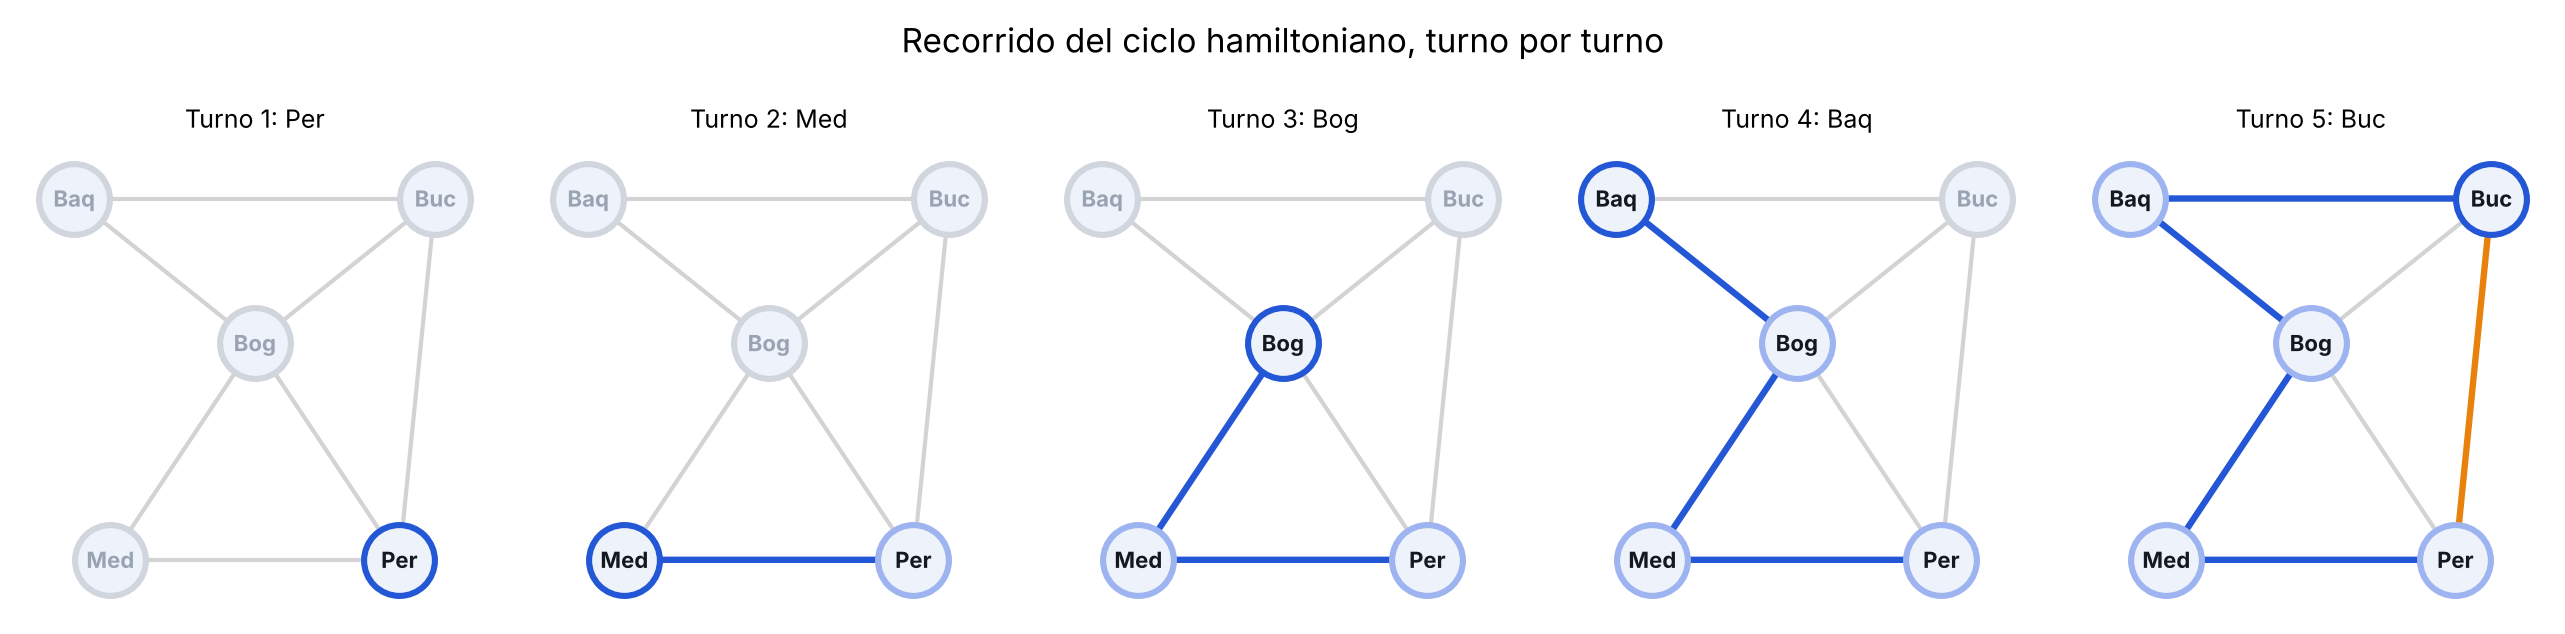

In [14]:
I = modelos['Reglas 1 a 5']
orden = H._orden(I)
print('Recorrido:', ' -> '.join(ciudades[c] for c in orden), '->', ciudades[orden[0]])
H.visualizar_por_turnos(I)

## Verificación de DPLL

### ¿Encuentra todos los ciclos?

Para saber si DPLL es **completo** le pedimos *todos* los modelos: cada vez que encuentra uno, agregamos una cláusula que lo prohíbe (alguna de las 25 letras $Visita(c,t)$ debe cambiar) y volvemos a correr, hasta que responda «insatisfacible». Lo comparamos con la fuerza bruta sobre las $5! = 120$ permutaciones de las ciudades usando la fórmula original.

In [15]:
originales = [H.Visita.ravel([c, t]) for c in range(H.n) for t in range(H.n)]

def todos_los_modelos(C):
    '''Enumera los modelos (restringidos a las letras Visita) con una cláusula de bloqueo por modelo.'''
    C = [list(cl) for cl in C]
    encontrados = []
    while True:
        I = dpll(C)
        if I is None:
            return encontrados
        J = {l: I.get(l, False) for l in originales}
        encontrados.append(J)
        C.append([('-' + l) if J[l] else l for l in originales])     # prohíbe este recorrido

def interp_de_recorrido(orden):
    '''Interpretación de las 25 letras Visita para un recorrido (tupla de nombres de ciudad).'''
    I = {l: False for l in originales}
    for t, nombre in enumerate(orden):
        I[H.Visita.ravel([ciudades.index(nombre), t])] = True
    return I

con_dpll = {tuple(ciudades[c] for c in H._orden(J)) for J in todos_los_modelos(clausulas['Reglas 1 a 5'])}
fuerza_bruta = {p for p in permutations(ciudades) if arboles['Reglas 1 a 5'].valor(interp_de_recorrido(p))}

print('Recorridos que encuentra DPLL        :', len(con_dpll))
print('Recorridos que aceptan las reglas (A):', len(fuerza_bruta))
print('¿Son exactamente los mismos?         :', con_dpll == fuerza_bruta)
for p in sorted(con_dpll):
    print('  ', ' -> '.join(p), '->', p[0])

Recorridos que encuentra DPLL        : 10
Recorridos que aceptan las reglas (A): 10
¿Son exactamente los mismos?         : True
   Baq -> Bog -> Med -> Per -> Buc -> Baq
   Baq -> Buc -> Per -> Med -> Bog -> Baq
   Bog -> Baq -> Buc -> Per -> Med -> Bog
   Bog -> Med -> Per -> Buc -> Baq -> Bog
   Buc -> Baq -> Bog -> Med -> Per -> Buc
   Buc -> Per -> Med -> Bog -> Baq -> Buc
   Med -> Bog -> Baq -> Buc -> Per -> Med
   Med -> Per -> Buc -> Baq -> Bog -> Med
   Per -> Buc -> Baq -> Bog -> Med -> Per
   Per -> Med -> Bog -> Baq -> Buc -> Per


Son 10 recorridos, pero un solo ciclo: el mismo ciclo se puede empezar en cualquiera de las 5 ciudades y recorrer en 2 sentidos ($5 \times 2 = 10$).

### Un grafo sin ciclo hamiltoniano

El grafo del artículo agrega la carretera Buc–Per justamente para que exista un ciclo hamiltoniano. Si la quitamos, las reglas ya no se pueden cumplir y DPLL debe responder **insatisfacible**.

In [16]:
H2 = CicloHamiltoniano(ciudades, [a for a in aristas if a != {1, 4}], coords)    # sin Buc-Per
C2 = tseitin(Ytoria(H2.reglas))

stats2 = {}
I2 = dpll(C2, stats=stats2)
print('Sin la carretera Buc–Per:', 'modelo' if I2 is not None else 'sin modelo (insatisfacible)')
print('Estadísticas:', stats2)
print('Con las 5 reglas y las 7 carreteras sí hay modelo:', dpll(clausulas['Reglas 1 a 5']) is not None)

Sin la carretera Buc–Per: sin modelo (insatisfacible)
Estadísticas: {'decisiones': 23, 'unitarias': 2486, 'puros': 0, 'conflictos': 24}
Con las 5 reglas y las 7 carreteras sí hay modelo: True


### Heurística y literales puros

Corremos las cuatro combinaciones (`heuristica` × `puros`) sobre el problema con ciclo (satisfacible) y sobre el grafo sin la carretera Buc–Per (insatisfacible). Para el número de decisiones y de conflictos importa más la heurística que el reloj: los tiempos son de milisegundos.

In [17]:
filas = []
for caso, C in [('Con Buc–Per (satisfacible)', clausulas['Reglas 1 a 5']),
                ('Sin Buc–Per (insatisfacible)', C2)]:
    for heuristica in ('corta', 'frecuente'):
        for puros in (True, False):
            st = {}
            t0 = time.perf_counter()
            I_ = dpll(C, heuristica, puros, st)
            seg = time.perf_counter() - t0
            filas.append({'Caso': caso, 'Heurística': heuristica, 'Puros': puros,
                          'Resultado': 'modelo' if I_ is not None else 'sin modelo',
                          'Decisiones': st['decisiones'], 'Unitarias': st['unitarias'],
                          'Puros usados': st['puros'], 'Conflictos': st['conflictos'],
                          'Tiempo (s)': round(seg, 4)})
pd.DataFrame(filas)

,Caso,Heurística,Puros,Resultado,Decisiones,Unitarias,Puros usados,Conflictos,Tiempo (s)
0,Con Buc–Per (satisfacible),corta,True,modelo,7,312,0,0,0.0183
1,Con Buc–Per (satisfacible),corta,False,modelo,7,312,0,0,0.0232
2,Con Buc–Per (satisfacible),frecuente,True,modelo,9,644,0,3,0.0278
3,Con Buc–Per (satisfacible),frecuente,False,modelo,9,644,0,3,0.0330
4,Sin Buc–Per (insatisfacible),corta,True,sin modelo,23,2486,0,24,0.0811
5,Sin Buc–Per (insatisfacible),corta,False,sin modelo,23,2486,0,24,0.0742
6,Sin Buc–Per (insatisfacible),frecuente,True,sin modelo,21,2068,0,22,0.0777
7,Sin Buc–Per (insatisfacible),frecuente,False,sin modelo,21,2068,0,22,0.0737


## Tabla resumen

Reúne las filas de `resultados` (una por regla y una para las cinco juntas) y las guarda en `resultados/resultados_DPLL.csv`, con las mismas columnas que los demás solvers (`Solver, Regla, Resultado, ¿Verifica?, Tiempo (s)`) y tres más propias de DPLL. `Tiempo (s)` es solo el tiempo de DPLL; el de Tseitin va aparte en `Tseitin (s)`.

In [18]:
tabla = pd.DataFrame(list(resultados.values()))
tabla.to_csv(f'resultados/resultados_{SOLVER}.csv', index=False)
tabla

,Solver,Regla,Resultado,¿Verifica?,Tiempo (s),Tseitin (s),Nº cláusulas,Decisiones,Conflictos
0,DPLL,Regla 1,modelo,True,0.0006,0.0001,73,20,0
1,DPLL,Regla 2,modelo,True,0.0006,0.0001,73,20,0
2,DPLL,Regla 3,modelo,True,0.0061,0.0011,423,25,0
3,DPLL,Regla 4,modelo,True,0.0020,0.0005,226,20,0
4,DPLL,Regla 5,modelo,True,0.0002,0.0001,55,5,0
5,DPLL,Reglas 1 a 5,modelo,True,0.0183,0.0018,858,7,0


## Modelos a JSON

Guardamos `resultados/modelos_DPLL.json` con la misma estructura que los otros notebooks: por regla, el resultado, si verifica, el tiempo y el modelo (que incluye las letras auxiliares de Tseitin; al dibujar se ignoran). `extra` trae el tamaño de la forma clausal y lo que hizo DPLL.

In [19]:
modelos_DPLL = {'DPLL': {}}
for nombre, fila in resultados.items():
    modelos_DPLL['DPLL'][nombre] = {
        'resultado': fila['Resultado'],
        'verifica':  fila['¿Verifica?'],
        'tiempo_s':  fila['Tiempo (s)'],
        'modelo':    modelos.get(nombre),
        'extra': {
            'n_clausulas': fila['Nº cláusulas'],
            'decisiones':  fila['Decisiones'],
            'conflictos':  fila['Conflictos'],
        },
    }

with open('resultados/modelos_DPLL.json', 'w', encoding='utf-8') as f:
    json.dump(modelos_DPLL, f, ensure_ascii=False, indent=2)

print('Guardado resultados/modelos_DPLL.json')
for regla, datos in modelos_DPLL['DPLL'].items():
    print(f'  {regla:14s} → modelo: {datos["modelo"] is not None}')

Guardado resultados/modelos_DPLL.json
  Regla 1        → modelo: True
  Regla 2        → modelo: True
  Regla 3        → modelo: True
  Regla 4        → modelo: True
  Regla 5        → modelo: True
  Reglas 1 a 5   → modelo: True


## Lectura de resultados

**1. DPLL resuelve el problema completo sin ramificar casi nada.** Con las cinco reglas juntas (858 cláusulas de Tseitin) DPLL encuentra un modelo con solo **7 decisiones y 0 conflictos**: casi todo el trabajo lo hace la propagación de unitarias, y nunca hay que retroceder. El modelo se verifica contra las reglas originales con `A.valor` y se dibuja como un recorrido válido.

**2. Comparación con los otros solvers (CSV de los notebooks anteriores).** La tabla de verdad (`SATtabla`) tardó cerca de **106,8 s** en el problema completo, y los tableaux **no terminaron** (se cortaron por tiempo) en la regla 4 (anchura) ni en las reglas 1 a 5. DPLL resuelve todo en el orden de **milisegundos**. La diferencia viene de que DPLL no recorre las $2^{25}$ interpretaciones ni expande la fórmula en un árbol enorme: trabaja sobre cláusulas y descarta de golpe todo lo que la propagación ya decide.

**3. El costo de Tseitin es despreciable.** Pasar a forma clausal toma milisegundos y se calcula una sola vez (`datos/tseitin.json`). A cambio, la fórmula crece de forma lineal (una letra auxiliar por conectivo) y se conserva la satisfacibilidad, sin la explosión que tendría la FNC por distribución.

**4. Es correcto y completo.** Al enumerar todos los modelos con cláusulas de bloqueo, DPLL encuentra **exactamente los 10 recorridos** que aceptan las reglas originales (los mismos que la fuerza bruta sobre las 120 permutaciones: el ciclo `Baq–Bog–Med–Per–Buc` y sus rotaciones/sentidos). Si se quita la carretera Buc–Per, DPLL responde **insatisfacible**, como debe ser.

**5. Heurísticas y literales puros.**
- En el caso satisfacible, escoger el literal de la cláusula más corta (`corta`) necesita 7 decisiones frente a 9 de `frecuente`. En el insatisfacible pasa al revés: 21 decisiones con `frecuente` frente a 23 con `corta`. Ninguna gana siempre; la diferencia es pequeña con este tamaño.
- La regla del **literal puro nunca se usa** (0 en todas las corridas). Es normal: en Tseitin cada letra auxiliar aparece en ambas polaridades (por la equivalencia), así que casi no hay literales puros. Por eso activarla no cambia las decisiones, solo añade un poco de trabajo.

**Conclusión:** sobre la forma de Tseitin, DPLL es la opción práctica de los tres métodos «exactos» vistos: es correcto, resuelve el problema completo al instante y además detecta la insatisfacibilidad. Queda como referencia para comparar con WalkSAT (incompleto, aleatorio) y MiniSAT (CDCL) en `07_Comparacion.ipynb`.
